### Petroleo Brasileiro Petrobras SA DRC

In [1]:
import os
import datetime as dt

from dotenv import load_dotenv
from pathlib import Path

import json
import time
from urllib.parse import urljoin, urlencode
import requests

import numpy as np
import pandas as pd

import plotly
import plotly.graph_objs as go
import plotly.express as px
import seaborn as sns
import matplotlib.pyplot as plt

import statsmodels.api as sm

from scipy.stats import spearmanr
from scipy.stats import pearsonr
from scipy.stats import fisher_exact
from sklearn.metrics import roc_auc_score
from statsmodels.graphics.tsaplots import plot_acf
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    classification_report,
    roc_auc_score
)

from Modules.utility import Utility
from Modules.show_plot import ShowPlot
from Modules.request_api_v2 import RequestApi
from Modules.get_market_data import GetMarketData
from Modules.stock_prices_and_market_data import ClassStockPricesMarketData
from Modules.financial import Financial
from Modules.pdf_url_to_markdown import PDFUrlToMarkdown
from Modules.webpage_to_markdown import WebpageToMarkdown
from Modules.compute_fibonacci_extension import ComputeFibonacciExtension
from Modules.fibonacci_retracement import FibonacciRetracement
from Modules.fibonacci_extension import FibonacciExtension

In [2]:
# FRED API key for accessing Federal Reserve Economic Data
FRED_API_KEY = os.getenv("FRED_API_KEY")
# Output directory for storing downloaded data
API_BASE_URL = os.getenv("API_BASE_URL", "http://localhost:8000")
request_api = RequestApi(API_BASE_URL)
fred_url = "https://api.stlouisfed.org/fred/series/observations"
get_market_data = GetMarketData(Path('/workspace/data'))
utility = Utility()
stock_prices_market_data = ClassStockPricesMarketData()
financial = Financial()
# URLからPDFをダウンロードしてMarkdownに変換するクラスのインスタンスを作成
pdf_to_md = PDFUrlToMarkdown()
# WEBページをMarkdownに変換する関数
webpage_to_markdown = WebpageToMarkdown()
# Fibonacciエクステンションを計算するクラスのインスタンスを作成
fibonacci_extension = ComputeFibonacciExtension()
# Fibonacciエクステンションをプロットするクラスのインスタンスを作成
fibonacci_extension_v2 = FibonacciExtension() 
# Fibonacciリトレースメントを計算するクラスのインスタンスを作成
fibonacci_retracement = FibonacciRetracement()

#### WTIの時系列データを取得

In [3]:
wti = 'CL=F'
start = '1999-01-01'
end = dt.datetime.now().strftime('%Y-%m-%d')
wti_df = request_api.fetch_stock_timeseries_data(
    start_date=start,
    end_date=end,
    code=wti,
    market=None,
)
wti_df.tail()

取得件数: 6572


,id,stock_code,stock_market,date,open,high,low,close,volume,ma5,...,lower1,rci52,cross,gc,dc,macd_gc,macd_dc,rci_gc,rci_dc,rising_condition
6567,1333854,CL=F,None,2026-10-20,101.790001,110.480003,101.040001,103.430000,382038,98.534001,...,90.025431,67.924528,True,96.490001,NaN,NaN,NaN,NaN,NaN,False
6568,1333855,CL=F,None,2026-10-21,97.150002,100.400002,96.260002,98.190002,332174,99.222002,...,90.184721,66.404849,True,NaN,NaN,NaN,NaN,NaN,NaN,False
6569,1333856,CL=F,None,2026-10-22,99.470001,100.169998,97.720001,97.779999,301805,99.740001,...,90.235616,64.799795,True,NaN,NaN,NaN,NaN,NaN,NaN,False
6570,1333857,CL=F,None,2026-10-23,103.269997,103.919998,98.839996,99.099998,331867,100.050000,...,90.266780,63.348416,True,NaN,NaN,NaN,NaN,NaN,NaN,False
6571,1340448,CL=F,None,2026-10-26,101.760002,103.129997,100.330002,102.610001,331867,100.222000,...,90.214081,63.041065,True,NaN,NaN,NaN,NaN,NaN,NaN,False


#### S&P500の時系列データを取得

In [4]:
sp500 = '^GSPC'
sp500_df = request_api.fetch_stock_timeseries_data(
    start_date=start,
    end_date=end,
    code=sp500,
    market=None,
)
sp500_df.tail()

取得件数: 7027


,id,stock_code,stock_market,date,open,high,low,close,volume,ma5,...,lower1,rci52,cross,gc,dc,macd_gc,macd_dc,rci_gc,rci_dc,rising_condition
7022,1322447,^GSPC,None,2026-10-20,7712.569824,7748.419922,7668.029785,7679.009766,5004770000,7717.717969,...,7667.092991,10.475540,False,NaN,7723.472031,NaN,NaN,NaN,NaN,False
7023,1322449,^GSPC,None,2026-10-21,7757.169922,7770.399902,7709.339844,7736.430176,4921480000,7710.167969,...,7678.297169,14.249125,False,NaN,NaN,NaN,NaN,NaN,NaN,False
7024,1332253,^GSPC,None,2026-10-22,7663.430176,7702.939941,7637.359863,7694.620117,5972620000,7711.629980,...,7684.296682,16.289593,False,NaN,NaN,NaN,NaN,NaN,NaN,False
7025,1332261,^GSPC,None,2026-10-23,7623.680176,7660.149902,7612.069824,7637.180176,5062330000,7690.002051,...,7682.095087,15.555366,False,NaN,NaN,NaN,NaN,NaN,NaN,False
7026,1340449,^GSPC,None,2026-10-26,7676.770020,7702.129883,7639.700195,7639.700195,5838070000,7677.388086,...,7677.272749,14.983352,False,NaN,NaN,NaN,NaN,NaN,NaN,False


#### PBRの時系列データを取得

In [5]:
pbr = 'PBR'
pbr_df = request_api.fetch_stock_timeseries_data(
    start_date=start,
    end_date=end,
    code=pbr,
    market=None,
)
pbr_df.tail()

取得件数: 6591


,id,stock_code,stock_market,date,open,high,low,close,volume,ma5,...,lower1,rci52,cross,gc,dc,macd_gc,macd_dc,rci_gc,rci_dc,rising_condition
6586,1340444,PBR,None,2026-10-20,25.700001,26.040001,25.299999,26.040001,21629500,25.778,...,20.639131,89.772048,True,NaN,NaN,NaN,NaN,NaN,NaN,False
6587,1340445,PBR,None,2026-10-21,25.660000,26.040001,25.660000,25.889999,16163500,25.828,...,20.759205,90.480663,True,NaN,NaN,NaN,NaN,NaN,NaN,False
6588,1340446,PBR,None,2026-10-22,25.620001,25.990000,25.090000,25.940001,13122200,25.892,...,20.943448,90.540425,True,NaN,NaN,NaN,NaN,NaN,NaN,False
6589,1340447,PBR,None,2026-10-23,26.160000,26.389999,25.790001,25.959999,25136000,25.946,...,21.149030,90.796551,True,NaN,NaN,NaN,NaN,NaN,NaN,False
6590,1340450,PBR,None,2026-10-26,22.500000,22.760000,21.360001,21.709999,102563900,25.108,...,21.225987,89.780586,True,NaN,NaN,NaN,1.316264,NaN,NaN,False


#### チャート

In [6]:
def stock_prices_and_oil_prices(
        code: str,
        name: str,
        start: str,
        end: str,
        df_sp: pd.DataFrame | None = None,
        df_wti: pd.DataFrame | None = None,
        #df_silver: pd.DataFrame | None = None,
    ):
    # /api/v1/time_series_data/stock/
    response = request_api.get_stock_time_series_data(
        code=code,
        market=None,
        start=start,
        end=end
    )
    df_stock = pd.DataFrame(response)

    # S&P500を統合
    if df_sp is not None:
        df_sp_tmp = df_sp.copy() if df_sp is not None else pd.DataFrame()
        if "date" not in df_sp_tmp.columns:
            df_sp_tmp = df_sp_tmp.reset_index()

        df_sp_tmp["date"] = pd.to_datetime(df_sp_tmp["date"])
        df_sp_tmp = df_sp_tmp.set_index("date")
        df_sp_tmp = df_sp_tmp.loc[start:end]

    # WTI原油価格を統合
    if df_wti is not None:
        df_wti_tmp = df_wti.copy() if df_wti is not None else pd.DataFrame()
        if "date" not in df_wti_tmp.columns:
            df_wti_tmp = df_wti_tmp.reset_index()
        df_wti_tmp["date"] = pd.to_datetime(df_wti_tmp["date"])
        df_wti_tmp = df_wti_tmp.set_index("date")
        df_wti_tmp = df_wti_tmp.loc[start:end]

    # 株価時系列データを整形
    df = df_stock.copy()
    df["date"] = pd.to_datetime(df["date"])
    df = df.set_index("date")
    df = df.loc[start:end]


    # インデックスを揃えて結合
    if df_sp is not None:
        df["MA50_SP"] = df_sp_tmp["ma50"].reindex(df.index)
        df["MA200_SP"] = df_sp_tmp["ma200"].reindex(df.index)
    if df_wti is not None:
        df["MA50_WTI"] = df_wti_tmp["ma50"].reindex(df.index)
        df["MA200_WTI"] = df_wti_tmp["ma200"].reindex(df.index)

    show_plot = ShowPlot()
    fig = show_plot.create_basic_chart(
        df=df.reset_index(),
        code=code,
        name=name,
        start=start,
        end=end,
        ma5=False,
        ma25=False,
        ma50=True,
        ma100=False,
        ma150=False,
        ma200=True,
    )
    # ★ 2つのY軸を定義（左：HYMC、右：SP500 & GOLD）
    fig.update_layout(
        yaxis=dict(
            title=f"{name} Price",
            side="left"
        ),
        yaxis2=dict(
            title="SP500 / WTI",
            overlaying="y",
            side="right"
        )
    )

    # --- SP500（右軸） ---
    if df_sp is not None:
        fig.add_trace(
            go.Scatter(
                x=df.index,
                y=df["MA50_SP"],
                name="SP_MA50",
                line={"color": "blue", "width": 1.2},
                yaxis="y2"   # ★ 右軸
            )
        )
        fig.add_trace(
            go.Scatter(
                x=df.index,
                y=df["MA200_SP"],
                name="SP_MA200",
                line={"color": "gray", "width": 1.2},
                yaxis="y2"   # ★ 右軸
            )
        )

    # --- WTI（右軸） ---
    if df_wti is not None:
        fig.add_trace(
            go.Scatter(
                x=df.index,
                y=df["MA50_WTI"],
                name="WTI_MA50",
                line={"color": "orange", "width": 1.2},
                yaxis="y2"   # ★ 右軸
            )
        )
        fig.add_trace(
            go.Scatter(
                x=df.index,
                y=df["MA200_WTI"],
                name="WTI_MA200",
                line={"color": "yellow", "width": 1.2},
                yaxis="y2"   # ★ 右軸
            )
        )

    return fig

In [7]:
name = "Petroleo Brasileiro Petrobras SA DRC"
start = dt.datetime(2025, 1, 1).strftime("%Y-%m-%d")
# グラフ領域の作成
fig = stock_prices_and_oil_prices(
    code=pbr,
    name=name,
    start=start,
    end=end,
    df_sp=None,
    df_wti=wti_df
)
fig.show()

取得件数: 662


In [8]:
# 例: すでに作成済みの fig を保存
output_dir = Path("/workspace/data/figures")
output_dir.mkdir(parents=True, exist_ok=True)
# ファイル名にコードと期間を含める
output_path = output_dir / f"{pbr}_{start}_{end}.png"
# 重複するファイルがある場合は削除
if output_path.exists():
    output_path.unlink()
# 保存
fig.write_image(str(output_path), width=1600, height=900, scale=2)
# 保存完了のメッセージを表示
print("saved:", output_path)

saved: /workspace/data/figures/PBR_2025-01-01_2026-10-27.png


#### 時系列データを保存

In [9]:
output_dir = Path("/workspace/data/")
output_dir.mkdir(parents=True, exist_ok=True)
output_path = output_dir / f"{pbr}_data_{dt.datetime.now().strftime('%Y-%m-%d')}.csv"
# 重複するファイルがある場合は削除
if output_path.exists():
    output_path.unlink()
# 保存
df = pbr_df.copy()
df = df.reset_index()
df["date"] = pd.to_datetime(df["date"])
df = df.set_index("date")
df = df.loc['2026-01-01':end]
df.to_csv(output_path)
df.head()

,index,id,stock_code,stock_market,open,high,low,close,volume,ma5,...,lower1,rci52,cross,gc,dc,macd_gc,macd_dc,rci_gc,rci_dc,rising_condition
date,,,,,,,,,,,,,,,,,,,,,
2026-01-02,6386,1340244,PBR,None,11.424888,11.453641,11.242779,11.386549,10001800,11.221694,...,11.245657,-7.103219,False,NaN,NaN,NaN,NaN,-40.0,NaN,True
2026-01-05,6387,1340245,PBR,None,11.252364,11.396134,11.012748,11.338626,28166500,11.283036,...,11.223672,-14.863827,False,NaN,NaN,NaN,NaN,NaN,NaN,False
2026-01-06,6388,1340246,PBR,None,11.089426,11.396135,11.070257,11.329042,21177900,11.332876,...,11.202131,-22.897635,False,NaN,NaN,NaN,NaN,NaN,NaN,False
2026-01-07,6389,1340247,PBR,None,11.060672,11.108595,11.003164,11.060672,15302100,11.292620,...,11.161483,-33.381713,False,2.294451,NaN,NaN,NaN,NaN,NaN,False
2026-01-08,6390,1340248,PBR,None,11.309873,11.367380,11.108595,11.108595,17034500,11.244697,...,11.129448,-38.546914,False,NaN,NaN,NaN,NaN,NaN,NaN,False


#### Fibonacci Extension

{'fib_levels_down': {'1.000': np.float64(15.408075560805614),
  '1.272': np.float64(12.420992279360366),
  '1.382': np.float64(11.212980658187654),
  '1.618': np.float64(8.62124663458075)},
 'fib_levels_up': {'1.272': np.float64(29.377082671093685),
  '1.382': np.float64(30.585094292266398),
  '1.618': np.float64(33.1768283158733),
  '2.000': np.float64(37.37192321849126)},
 'swing_high': np.float64(26.389999389648438),
 'swing_low': np.float64(15.408075560805614),
 'df_with_fib':       index       id stock_code stock_market       date       open       high  \
 0         0  1333858        PBR         None 2000-08-10   1.202065   1.202065   
 1         1  1333859        PBR         None 2000-08-11   1.199440   1.223061   
 2         2  1333860        PBR         None 2000-08-14   1.194191   1.212563   
 3         3  1333861        PBR         None 2000-08-15   1.199440   1.236184   
 4         4  1333862        PBR         None 2000-08-16   1.230935   1.259806   
 ...     ...      ...  

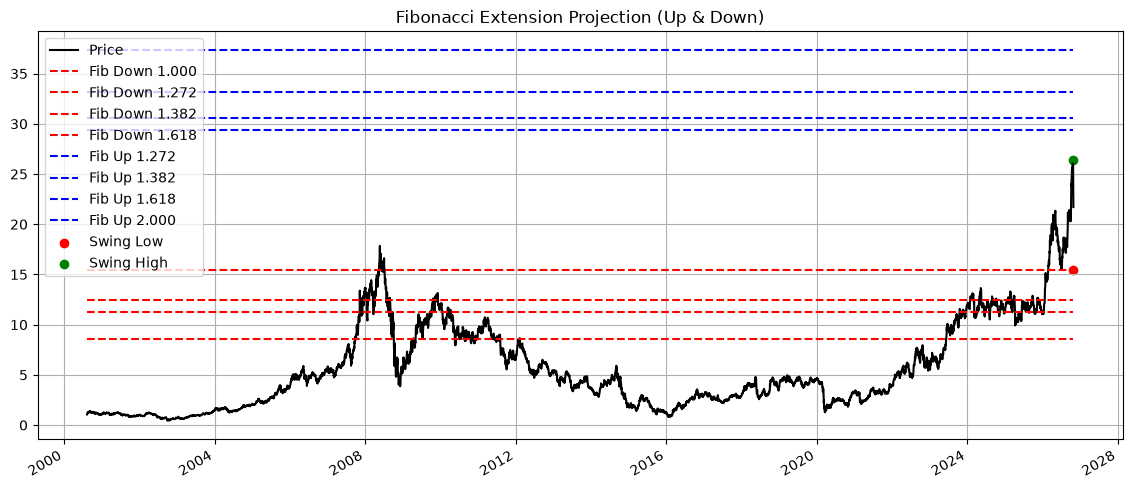

In [10]:
fib_result = fibonacci_extension.compute_fibonacci_extension(pbr_df.copy().reset_index())
fib_result

In [11]:
output_dir = Path("/workspace/data/figures/")
output_dir.mkdir(parents=True, exist_ok=True)
output_path = output_dir / f"{pbr}_fibonacci_extension_{dt.datetime.now().strftime('%Y-%m-%d')}.png"
# 重複するファイルがある場合は削除
if output_path.exists():
    output_path.unlink()
# 保存
fib_result["plot_obj"].savefig(output_path, dpi=300, bbox_inches="tight")
# 保存完了のメッセージを表示
print("saved:", output_path)

saved: /workspace/data/figures/PBR_fibonacci_extension_2026-10-27.png
